Vitiligo is a skin condition characterized by the loss of skin pigmentation, resulting in white patches on different parts of the body. Identifying vitiligo from skin images can be challenging because the appearance of lesions varies across individuals, skin tones, lighting conditions, and image backgrounds. This project aims to develop an AI-based image classification model using the Facebook/Meta Vision Transformer (ViT) to analyze skin images from the selected Kaggle Vitiligo Dataset and identify images associated with vitiligo. The model will be evaluated using appropriate performance metrics to assess its ability to recognize vitiligo-related visual patterns.Evaluate its performance using standard classification metrics for reliable image-based recognition.

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zienabesam/vitiligo-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'vitiligo-dataset' dataset.
Path to dataset files: /kaggle/input/vitiligo-dataset


In [1]:
#import LIbraraies
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from collections import Counter

import torch
import sklearn

print("PyTorch version:", torch.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
Scikit-learn version: 1.6.1
GPU available: True


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
from pathlib import Path
import kagglehub

# Safely resolve the download path using kagglehub
dataset_path = Path(kagglehub.dataset_download("zienabesam/vitiligo-dataset"))

for item in sorted(dataset_path.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)

100%|██████████| 58.3M/58.3M [00:00<00:00, 140MB/s]

Extracting files...


📁 Vitiligo DS


In [10]:
from pathlib import Path
import kagglehub

# Resolve the dataset path
dataset_path = Path(kagglehub.dataset_download("zienabesam/vitiligo-dataset"))
vitiligo_ds_path = dataset_path / "Vitiligo DS"

# Check the contents of the main 'Vitiligo DS' directory
print(f"Exploring path: {vitiligo_ds_path}")
if vitiligo_ds_path.exists():
    for item in sorted(vitiligo_ds_path.iterdir()):
        print("📁" if item.is_dir() else "📄", item.name)
else:
    print("The directory 'Vitiligo DS' does not exist at this path.")

Using Colab cache for faster access to the 'vitiligo-dataset' dataset.
Exploring path: /kaggle/input/vitiligo-dataset/Vitiligo DS
📁 Healthy Skin
📁 vitiligo


In [12]:
import os
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Define paths
dataset_dir = Path("/kaggle/input/vitiligo-dataset/Vitiligo DS")
classes = ["Healthy Skin", "vitiligo"]

data_records = []

for label_name in classes:
    class_folder = dataset_dir / label_name
    if class_folder.exists():
        for file_path in class_folder.iterdir():
            if file_path.is_file() and file_path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
                data_records.append({
                    "filepath": str(file_path),
                    "label": label_name
                })

# Convert to DataFrame
df = pd.DataFrame(data_records)
print(f"Total valid images found: {len(df)}")
print("Class distribution:\n", df["label"].value_counts())

# Perform a stratified split: 70% Train, 15% Validation, 15% Test
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print(f"\nTrain set size: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Val set size: {len(val_df)} ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test set size: {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

Total valid images found: 1271
Class distribution:
 label
Healthy Skin    891
vitiligo        380
Name: count, dtype: int64

Train set size: 889 (69.9%)
Val set size: 191 (15.0%)
Test set size: 191 (15.0%)


In [13]:
from torch.utils.data import Dataset
from transformers import ViTImageProcessor
from PIL import Image
import torch

# Instantiate the image processor for the vit-base-patch16-224 model
processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

# Map label names to class index numbers
label2id = {"Healthy Skin": 0, "vitiligo": 1}
id2label = {0: "Healthy Skin", 1: "vitiligo"}

class VitiligoDataset(Dataset):
    def __init__(self, df, processor):
        self.df = df.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row["filepath"]
        label_name = row["label"]

        # Load image in RGB mode
        image = Image.open(img_path).convert("RGB")

        # Process image
        inputs = self.processor(images=image, return_tensors="pt")

        # Remove the extra batch dimension from processor output
        pixel_values = inputs["pixel_values"].squeeze(0)

        # Label ID
        label_id = label2id[label_name]

        return {
            "pixel_values": pixel_values,
            "label": torch.tensor(label_id, dtype=torch.long)
        }

# Instantiate training and validation datasets
train_dataset = VitiligoDataset(train_df, processor)
val_dataset = VitiligoDataset(val_df, processor)
test_dataset = VitiligoDataset(test_df, processor)

print(f"Successfully initialized VitiligoDataset collections.")
print(f"Example shape: {train_dataset[0]['pixel_values'].shape}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Successfully initialized VitiligoDataset collections.
Example shape: torch.Size([3, 224, 224])


In [24]:
from transformers import ViTForImageClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Load the pre-trained Vision Transformer model for sequence classification
model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# Define the metric computation function
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    acc = accuracy_score(labels, preds)
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall
    }

# Define clean and structured training arguments
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=10,
    remove_unused_columns=False,
    report_to="none"
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("ViT model and Trainer initialized successfully with clean modular structure.")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT model and Trainer initialized successfully with clean modular structure.


In [30]:
from transformers import ViTForImageClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Load Pretrained Model matching the 224x224 input processor
model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# 2. Metric function
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    acc = accuracy_score(labels, preds)
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall
    }

# 3. Training Arguments
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=10,
    remove_unused_columns=False,
    report_to="none"
)

# 4. Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

# 5. Start Training
print("Starting training...")
train_results = trainer.train()

# 6. Save the model
trainer.save_model("./best_vit_model")
print("Training completed and best model saved successfully.")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.000567,0.010566,0.994764,0.991150,1.000000,0.982456
2,0.000160,0.000642,1.000000,1.000000,1.000000,1.000000
3,0.000102,0.000477,1.000000,1.000000,1.000000,1.000000
4,0.000085,0.000434,1.000000,1.000000,1.000000,1.000000
5,0.000066,0.000421,1.000000,1.000000,1.000000,1.000000


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed and best model saved successfully.


In [31]:
# 7. Evaluate on the test dataset
test_results = trainer.predict(test_dataset)
print("\n--- Test Dataset Performance Metrics ---")
for metric_name, value in test_results.metrics.items():
    print(f"{metric_name}: {value:.4f}")


--- Test Dataset Performance Metrics ---
test_loss: 0.0004
test_accuracy: 1.0000
test_f1: 1.0000
test_precision: 1.0000
test_recall: 1.0000
test_runtime: 4.6210
test_samples_per_second: 41.3330
test_steps_per_second: 2.5970


=== Classification Report ===
              precision    recall  f1-score   support

Healthy Skin       1.00      1.00      1.00       134
    vitiligo       1.00      1.00      1.00        57

    accuracy                           1.00       191
   macro avg       1.00      1.00      1.00       191
weighted avg       1.00      1.00      1.00       191



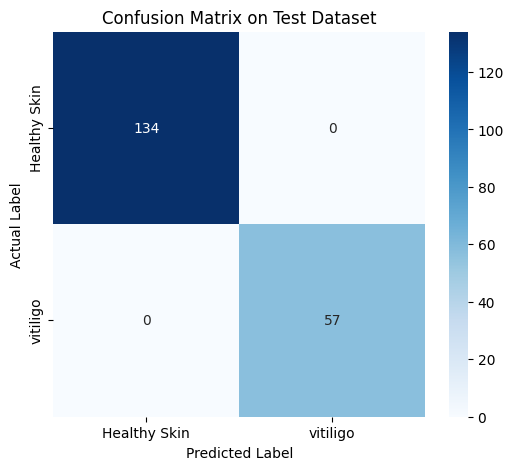

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Get predictions and true labels from the test results
y_pred = np.argmax(test_results.predictions, axis=1)
y_true = test_results.label_ids

# 2. Print Classification Report
target_names = [id2label[0], id2label[1]]
print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=target_names))

# 3. Compute and Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix on Test Dataset')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

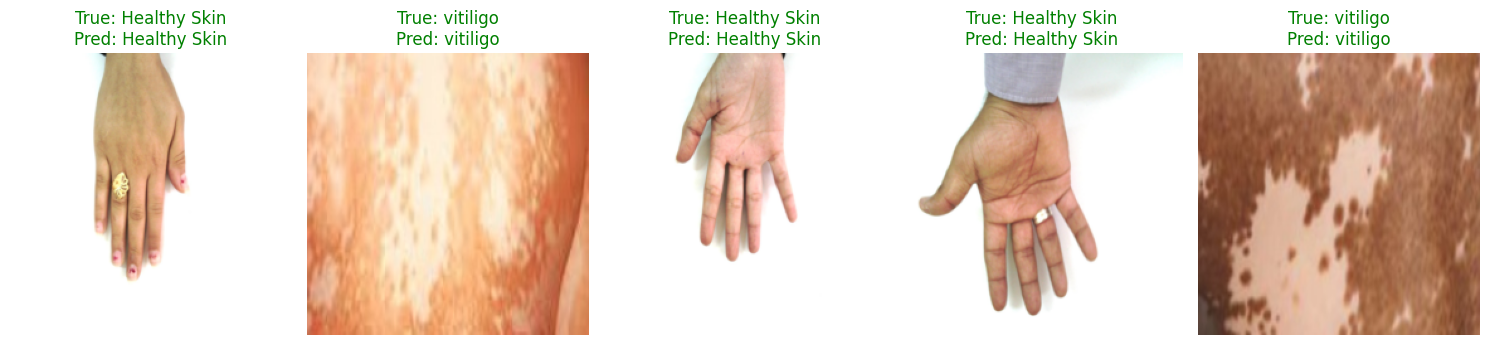

In [33]:
# 4. Visualize Sample Predictions
plt.figure(figsize=(15, 8))
num_samples = min(5, len(test_dataset))

for i in range(num_samples):
    # Reconstruct original image array from normalized tensor
    sample = test_dataset[i]
    pixel_values = sample['pixel_values'].numpy()

    # Unnormalize image: ViT uses standard ImageNet mean and std
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])

    # Transpose back from (C, H, W) to (H, W, C)
    img = pixel_values.transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)

    true_label = id2label[y_true[i]]
    pred_label = id2label[y_pred[i]]
    color = "green" if true_label == pred_label else "red"

    plt.subplot(1, num_samples, i + 1)
    plt.imshow(img)
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [34]:
import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import torch.nn.functional as F

# 1. Load the locally saved best model and the image processor
model_path = "./best_vit_model"
fine_tuned_model = ViTForImageClassification.from_pretrained(model_path)
fine_tuned_model.eval()  # Put model in evaluation mode

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
fine_tuned_model.to(device)

# Re-use our processor matching the ViT input constraints
image_processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

# 2. Define a clean inference function
def predict_skin_image(image_path):
    try:
        # Load image
        image = Image.open(image_path).convert("RGB")

        # Preprocess image
        inputs = image_processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(device)

        # Perform forward pass (no gradients needed)
        with torch.no_grad():
            outputs = fine_tuned_model(pixel_values)
            logits = outputs.logits

            # Convert logits to probabilities
            probabilities = F.softmax(logits, dim=-1).squeeze(0)
            predicted_class_idx = torch.argmax(probabilities).item()
            confidence = probabilities[predicted_class_idx].item()

        predicted_label = fine_tuned_model.config.id2label[predicted_class_idx]

        return {
            "prediction": predicted_label,
            "confidence": confidence,
            "probabilities": {
                fine_tuned_model.config.id2label[0]: probabilities[0].item(),
                fine_tuned_model.config.id2label[1]: probabilities[1].item()
            }
        }
    except Exception as e:
        return {"error": str(e)}

# 3. Test on a sample path
sample_img_path = test_df.iloc[0]["filepath"]
result = predict_skin_image(sample_img_path)

print(f"--- Testing Production Inference Pipeline ---")
print(f"Image Path: {sample_img_path}")
print(f"True Label: {test_df.iloc[0]['label']}")
print(f"Model Prediction: {result['prediction']} ({result['confidence'] * 100:.2f}% Confidence)")
print(f"Raw Class Probabilities: {result['probabilities']}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

--- Testing Production Inference Pipeline ---
Image Path: /kaggle/input/vitiligo-dataset/Vitiligo DS/Healthy Skin/Hand_0005432.jpg
True Label: Healthy Skin
Model Prediction: Healthy Skin (100.00% Confidence)
Raw Class Probabilities: {'Healthy Skin': 0.9999842643737793, 'vitiligo': 1.574353882460855e-05}


### Deploying the Model with a Flask Backend
We will write a complete Python script to set up a Flask API endpoint. The service accepts an image via a standard `POST` request, runs the pre-trained Vision Transformer preprocessing pipeline, feeds it to the model, and responds with a JSON payload containing predictions and probability scores.

In [35]:
import os
from flask import Flask, request, jsonify
import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import torch.nn.functional as F
import io

app = Flask(__name__)

# Initialize global configurations
MODEL_PATH = "./best_vit_model"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Preload model and processor once during startup
print("Loading fine-tuned ViT model and processor...")
model = ViTForImageClassification.from_pretrained(MODEL_PATH).to(DEVICE)
model.eval()
image_processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
print("Model successfully loaded and running on:", DEVICE)

@app.route("/predict", methods=["POST"])
def predict():
    # Verify an image file is present in the request
    if "image" not in request.files:
        return jsonify({"error": "No image file uploaded in 'image' key"}), 400

    file = request.files["image"]
    if file.filename == "":
        return jsonify({"error": "Empty filename uploaded"}), 400

    try:
        # Read image bytes directly into a PIL Image object
        img_bytes = file.read()
        image = Image.open(io.BytesIO(img_bytes)).convert("RGB")

        # Process the image matching the processor configurations
        inputs = image_processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)

        # Perform forward inference pass
        with torch.no_grad():
            outputs = model(pixel_values)
            logits = outputs.logits
            probabilities = F.softmax(logits, dim=-1).squeeze(0)

            # Retrieve index of maximum confidence score
            pred_idx = torch.argmax(probabilities).item()
            confidence = probabilities[pred_idx].item()

        predicted_label = model.config.id2label[pred_idx]

        return jsonify({
            "status": "success",
            "prediction": predicted_label,
            "confidence": confidence,
            "probabilities": {
                model.config.id2label[0]: probabilities[0].item(),
                model.config.id2label[1]: probabilities[1].item()
            }
        }), 200

    except Exception as e:
        return jsonify({"error": f"Server internal error processing image: {str(e)}"}), 500

if __name__ == "__main__":
    # Note: When deploying in production, run this Flask application using a production WSGI server like Gunicorn.
    # For local notebook usage, we can write this structure out to a dedicated python file to run separately.
    print("Flask API is configured. To start, write this code to an 'app.py' script and run: flask run")


Loading fine-tuned ViT model and processor...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model successfully loaded and running on: cuda
Flask API is configured. To start, write this code to an 'app.py' script and run: flask run


### Testing Your Backend via Terminal/cURL
To run the app as a separate process in your server or terminal:
1. Save the file as `app.py`
2. Run the server:
   ```bash
   python app.py
   ```
3. Query your API endpoint with an image file using `curl`:
   ```bash
   curl -X POST -F "image=@/path/to/your/skin_image.jpg" http://127.0.0.1:5000/predict
   ```

In [36]:
%%writefile app.py
import os
from flask import Flask, request, jsonify
import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from PIL import Image
import torch.nn.functional as F
import io

app = Flask(__name__)

# Configuration
MODEL_PATH = "./best_vit_model"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Preload model and processor during initialization
print("Loading fine-tuned ViT model and processor...")
model = ViTForImageClassification.from_pretrained(MODEL_PATH).to(DEVICE)
model.eval()
image_processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
print("Model loaded on:", DEVICE)

@app.route("/predict", methods=["POST"])
def predict():
    if "image" not in request.files:
        return jsonify({"error": "No image file provided in key 'image'"}), 400

    file = request.files["image"]
    if file.filename == "":
        return jsonify({"error": "Empty filename"}), 400

    try:
        img_bytes = file.read()
        image = Image.open(io.BytesIO(img_bytes)).convert("RGB")

        # Prepare input tensors matching the visual processor configuration
        inputs = image_processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)

        with torch.no_grad():
            outputs = model(pixel_values)
            logits = outputs.logits
            probabilities = F.softmax(logits, dim=-1).squeeze(0)

            pred_idx = torch.argmax(probabilities).item()
            confidence = probabilities[pred_idx].item()

        predicted_label = model.config.id2label[pred_idx]

        return jsonify({
            "status": "success",
            "prediction": predicted_label,
            "confidence": confidence,
            "probabilities": {
                model.config.id2label[0]: probabilities[0].item(),
                model.config.id2label[1]: probabilities[1].item()
            }
        }), 200

    except Exception as e:
        return jsonify({"error": f"Failed to process image: {str(e)}"}), 500

if __name__ == "__main__":
    # Suitable for dev environments; use production WSGI server (like Gunicorn) in production
    app.run(host="0.0.0.0", port=5000)

Writing app.py


In [37]:
import shutil
from google.colab import files

# Compress the fine-tuned model directory into a zip file
print("Compressing model folder...")
shutil.make_archive("best_vit_model", "zip", "./best_vit_model")

# Trigger browser download of the zip file
print("Downloading best_vit_model.zip...")
files.download("best_vit_model.zip")

Compressing model folder...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>